In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Dataset location
DATASET_DIR = Path("../data/processed/tomato_potato")

# Collect class information
class_counts = {}

for class_dir in sorted(DATASET_DIR.iterdir()):
    if class_dir.is_dir():
        image_count = len([
            f for f in class_dir.iterdir()
            if f.is_file()
        ])
        class_counts[class_dir.name] = image_count

# Create DataFrame
df_counts = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image_Count"]
)

df_counts

,Class,Image_Count
0,Potato___Early_blight,1000
1,Potato___healthy,152
2,Potato___Late_blight,1000
3,Tomato___Bacterial_spot,2127
4,Tomato___Early_blight,1000
5,Tomato___healthy,1585
6,Tomato___Late_blight,1901
7,Tomato___Leaf_Mold,952
8,Tomato___Septoria_leaf_spot,1771
9,Tomato___Spider_mites Two-spotted_spider_mite,1676


In [2]:
total_images = df_counts["Image_Count"].sum()

print("Number of classes:", len(df_counts))
print("Total images:", total_images)

Number of classes: 13
Total images: 20298


In [3]:
df_counts["Percentage"] = (
    df_counts["Image_Count"] / total_images * 100
).round(2)

df_counts.sort_values(
    "Image_Count",
    ascending=False
)

,Class,Image_Count,Percentage
12,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,26.39
3,Tomato___Bacterial_spot,2127,10.48
6,Tomato___Late_blight,1901,9.37
8,Tomato___Septoria_leaf_spot,1771,8.72
9,Tomato___Spider_mites Two-spotted_spider_mite,1676,8.26
5,Tomato___healthy,1585,7.81
10,Tomato___Target_Spot,1404,6.92
2,Potato___Late_blight,1000,4.93
0,Potato___Early_blight,1000,4.93
4,Tomato___Early_blight,1000,4.93


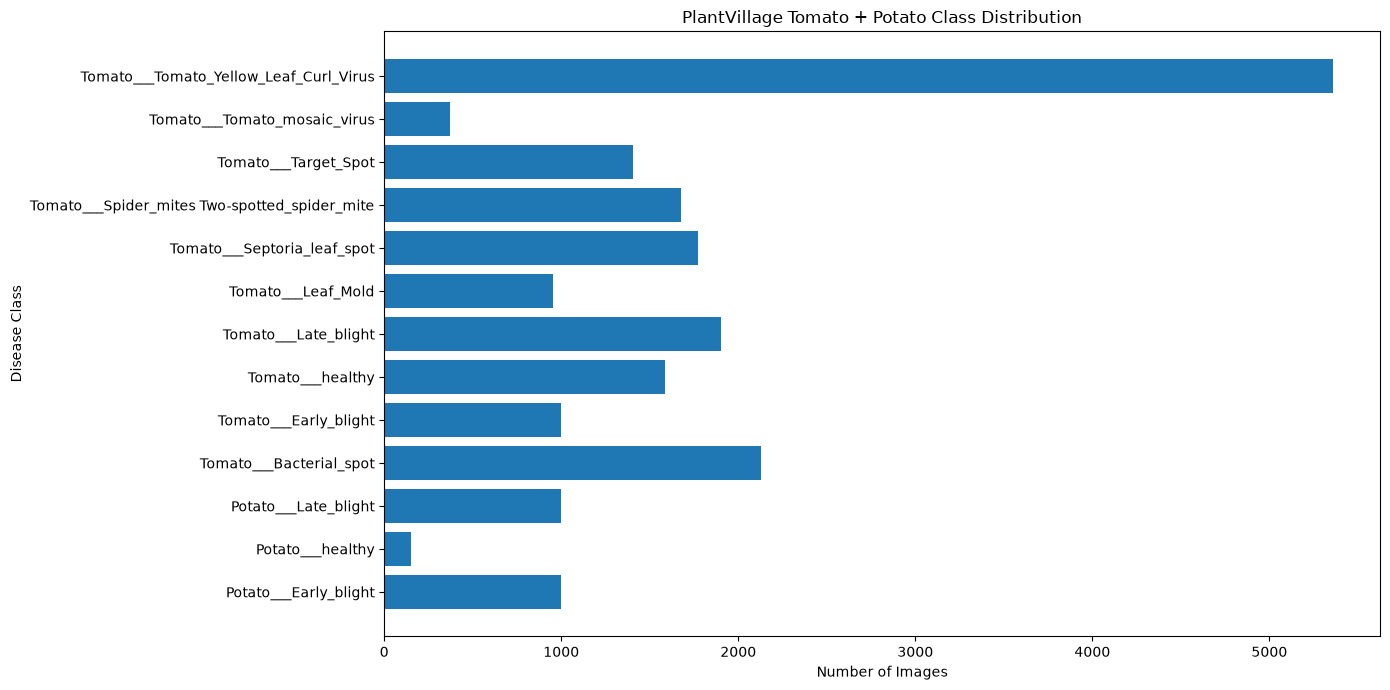

In [4]:
plt.figure(figsize=(14, 7))

plt.barh(
    df_counts["Class"],
    df_counts["Image_Count"]
)

plt.xlabel("Number of Images")
plt.ylabel("Disease Class")
plt.title("PlantVillage Tomato + Potato Class Distribution")

plt.tight_layout()
plt.show()

In [5]:
from pathlib import Path
from PIL import Image
from collections import Counter

DATASET_DIR = Path("../data/processed/tomato_potato")

image_extensions = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}

dimensions = []
formats = Counter()
corrupt_images = []

for class_dir in sorted(DATASET_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():

        if image_path.suffix not in image_extensions:
            continue

        try:
            with Image.open(image_path) as img:
                dimensions.append(img.size)
                formats[img.format] += 1

        except Exception as e:
            corrupt_images.append(str(image_path))

print("Total readable images:", len(dimensions))
print("Corrupt/unreadable images:", len(corrupt_images))
print("\nImage formats:")
for fmt, count in formats.items():
    print(f"{fmt}: {count}")

Total readable images: 20298
Corrupt/unreadable images: 0

Image formats:
JPEG: 20298


In [6]:
dimension_counts = Counter(dimensions)

print("Number of unique image dimensions:", len(dimension_counts))

print("\nMost common dimensions:")
for dimension, count in dimension_counts.most_common(15):
    print(f"{dimension}: {count}")

Number of unique image dimensions: 1

Most common dimensions:
(256, 256): 20298


In [7]:
widths = [w for w, h in dimensions]
heights = [h for w, h in dimensions]

print("Minimum width:", min(widths))
print("Maximum width:", max(widths))

print("Minimum height:", min(heights))
print("Maximum height:", max(heights))

Minimum width: 256
Maximum width: 256
Minimum height: 256
Maximum height: 256


In [8]:
aspect_ratios = [round(w / h, 3) for w, h in dimensions]

print("Minimum aspect ratio:", min(aspect_ratios))
print("Maximum aspect ratio:", max(aspect_ratios))

Minimum aspect ratio: 1.0
Maximum aspect ratio: 1.0


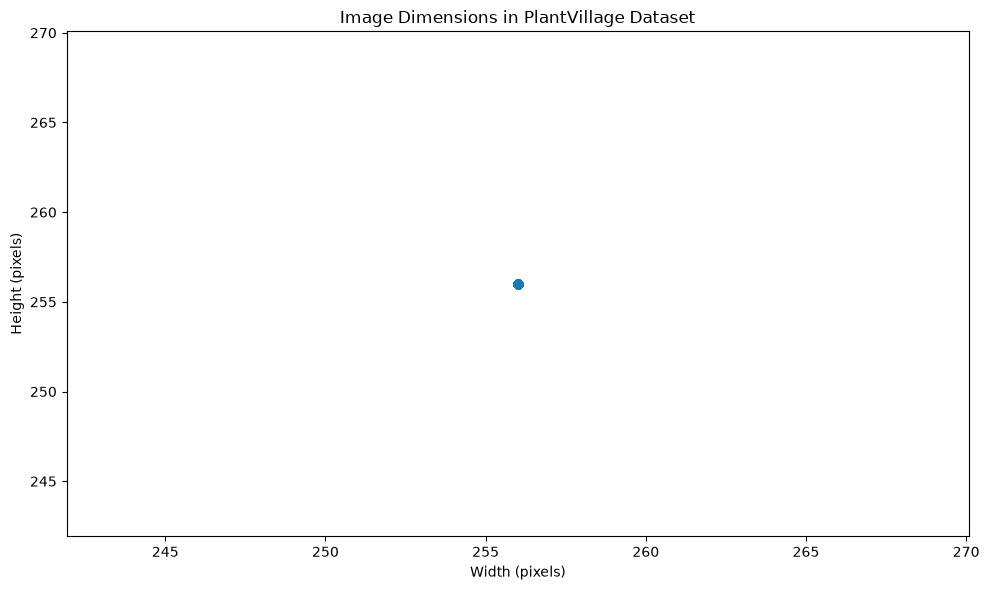

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(widths, heights, alpha=0.3)

plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.title("Image Dimensions in PlantVillage Dataset")

plt.tight_layout()
plt.show()

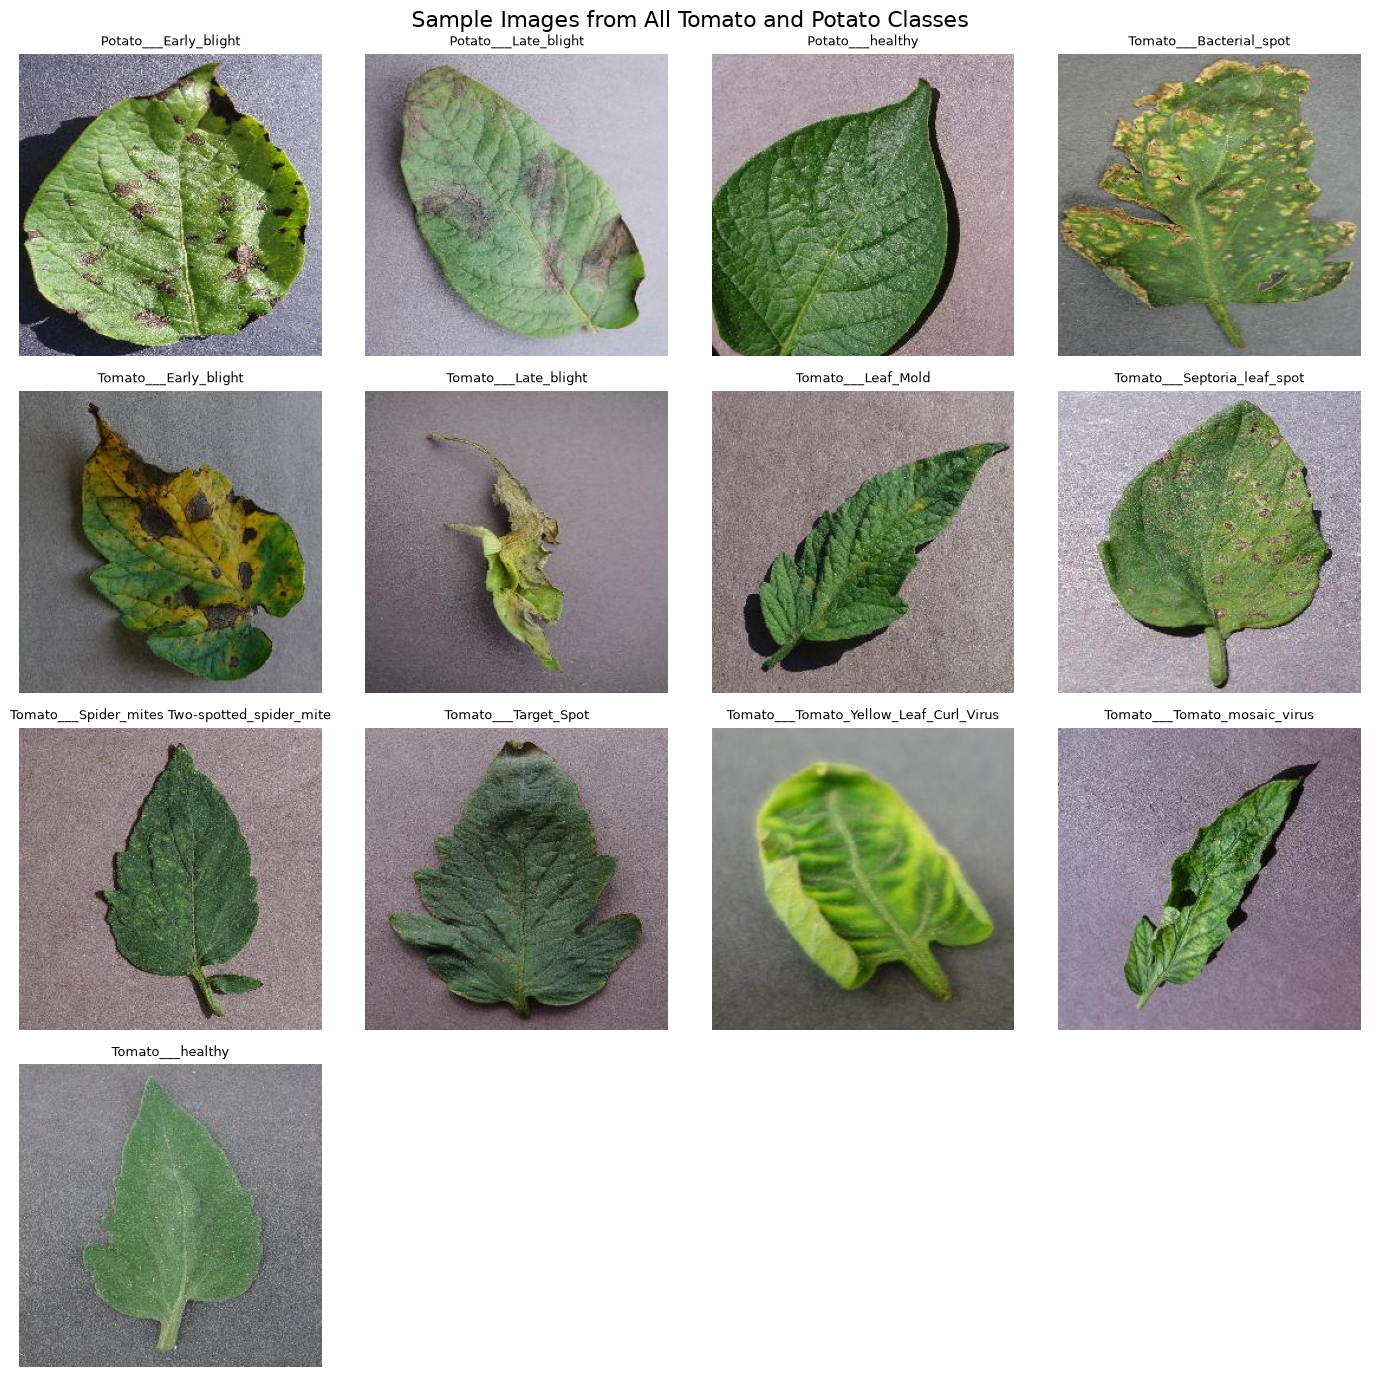

In [10]:
import random
from PIL import Image
import matplotlib.pyplot as plt

random.seed(42)

classes = sorted([
    folder.name
    for folder in DATASET_DIR.iterdir()
    if folder.is_dir()
])

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
axes = axes.flatten()

for i, class_name in enumerate(classes):

    class_dir = DATASET_DIR / class_name

    image_files = [
        f for f in class_dir.iterdir()
        if f.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    image_path = random.choice(image_files)

    image = Image.open(image_path)

    axes[i].imshow(image)
    axes[i].set_title(class_name, fontsize=9)
    axes[i].axis("off")

# Hide unused subplot spaces
for i in range(len(classes), len(axes)):
    axes[i].axis("off")

plt.suptitle(
    "Sample Images from All Tomato and Potato Classes",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [11]:
import hashlib
from pathlib import Path
from collections import defaultdict

DATASET_DIR = Path("../data/processed/tomato_potato")

hash_to_files = defaultdict(list)

image_extensions = {".jpg", ".jpeg", ".png"}

for class_dir in sorted(DATASET_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():

        if image_path.suffix.lower() not in image_extensions:
            continue

        hasher = hashlib.md5()

        with open(image_path, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                hasher.update(chunk)

        file_hash = hasher.hexdigest()
        hash_to_files[file_hash].append(str(image_path))

# Find duplicate groups
duplicate_groups = {
    h: files
    for h, files in hash_to_files.items()
    if len(files) > 1
}

print("Total images checked:", sum(len(v) for v in hash_to_files.values()))
print("Unique image hashes:", len(hash_to_files))
print("Duplicate groups:", len(duplicate_groups))

Total images checked: 20298
Unique image hashes: 20298
Duplicate groups: 0


In [12]:
for i, (file_hash, files) in enumerate(duplicate_groups.items(), start=1):

    print(f"\n{'=' * 70}")
    print(f"Duplicate Group {i}")
    print(f"{'=' * 70}")

    for file in files:
        print(file)

In [13]:
cross_class_duplicates = []

for file_hash, files in duplicate_groups.items():

    classes = set(
        Path(file).parent.name
        for file in files
    )

    if len(classes) > 1:
        cross_class_duplicates.append({
            "hash": file_hash,
            "classes": classes,
            "files": files
        })

print("Total duplicate groups:", len(duplicate_groups))
print("Cross-class duplicate groups:", len(cross_class_duplicates))

if cross_class_duplicates:
    print("\nWARNING: Cross-class duplicates found!")
    for item in cross_class_duplicates:
        print(item)
else:
    print("\nNo cross-class duplicates found.")

Total duplicate groups: 0
Cross-class duplicate groups: 0

No cross-class duplicates found.


In [14]:
# Remove exact duplicate files while keeping the first copy
# Raw dataset remains untouched.

removed_duplicates = []

for file_hash, files in duplicate_groups.items():

    # Keep the first file
    files_to_remove = files[1:]

    for file in files_to_remove:
        file_path = Path(file)

        if file_path.exists():
            file_path.unlink()
            removed_duplicates.append(file)

print("Duplicate files removed:", len(removed_duplicates))

for file in removed_duplicates:
    print("Removed:", file)

Duplicate files removed: 0


In [15]:
# Recount images after duplicate removal

remaining_images = []

for class_dir in sorted(DATASET_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():
        if image_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            remaining_images.append(image_path)

print("Images after duplicate removal:", len(remaining_images))

Images after duplicate removal: 20298


In [16]:
from collections import defaultdict
import hashlib

hash_check = defaultdict(list)

for image_path in remaining_images:

    hasher = hashlib.md5()

    with open(image_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            hasher.update(chunk)

    hash_value = hasher.hexdigest()
    hash_check[hash_value].append(str(image_path))

remaining_duplicate_groups = {
    h: files
    for h, files in hash_check.items()
    if len(files) > 1
}

print("Images checked:", len(remaining_images))
print("Unique hashes:", len(hash_check))
print("Remaining duplicate groups:", len(remaining_duplicate_groups))

Images checked: 20298
Unique hashes: 20298
Remaining duplicate groups: 0


In [17]:
from pathlib import Path

DATASET_DIR = Path("../data/processed/tomato_potato")

print("Dataset exists:", DATASET_DIR.exists())
print("Dataset path:", DATASET_DIR.resolve())

Dataset exists: True
Dataset path: C:\Users\ATHARVA\Desktop\Mini project\ai-farmer-assistant\data\processed\tomato_potato


In [18]:
import cv2
import numpy as np
import pandas as pd

quality_results = []

image_extensions = {".jpg", ".jpeg", ".png"}

for class_dir in sorted(DATASET_DIR.iterdir()):

    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():

        if image_path.suffix.lower() not in image_extensions:
            continue

        image = cv2.imread(str(image_path))

        if image is None:
            continue

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        brightness = float(np.mean(gray))
        contrast = float(np.std(gray))
        sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())

        quality_results.append({
            "Class": class_dir.name,
            "File": image_path.name,
            "Path": str(image_path),
            "Brightness": brightness,
            "Contrast": contrast,
            "Sharpness": sharpness
        })

quality_df = pd.DataFrame(quality_results)

print("Images analyzed:", len(quality_df))


Images analyzed: 20298


In [19]:
quality_df[["Brightness", "Contrast", "Sharpness"]].describe()

,Brightness,Contrast,Sharpness
count,20298.000000,20298.000000,20298.000000
mean,116.825529,38.695678,4249.725774
std,16.545355,10.532061,4299.679610
min,8.246216,10.629742,5.019577
25%,107.092976,30.845764,842.381957
50%,116.982475,39.039847,3246.493692
75%,125.987808,46.514624,6374.997900
max,194.555527,80.729056,27109.052995


In [20]:
dark_images = quality_df[quality_df["Brightness"] < 30]
bright_images = quality_df[quality_df["Brightness"] > 225]
low_contrast_images = quality_df[quality_df["Contrast"] < 20]
blurry_images = quality_df[quality_df["Sharpness"] < 50]

print("Very dark images:", len(dark_images))
print("Very bright images:", len(bright_images))
print("Very low contrast images:", len(low_contrast_images))
print("Potentially blurry images:", len(blurry_images))

Very dark images: 75
Very bright images: 0
Very low contrast images: 626
Potentially blurry images: 414


In [21]:
import matplotlib.pyplot as plt
from PIL import Image


def show_quality_samples(df, title, metric, n=12, worst=True):

    if len(df) == 0:
        print(f"No images found for: {title}")
        return

    # Show the most extreme cases rather than random samples
    if worst:
        samples = df.sort_values(metric, ascending=True).head(n)
    else:
        samples = df.sort_values(metric, ascending=False).head(n)

    rows = 3
    cols = 4

    fig, axes = plt.subplots(rows, cols, figsize=(15, 11))
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, samples.iterrows()):

        image = Image.open(row["Path"])

        ax.imshow(image)

        class_name = row["Class"].replace("___", "\n")

        ax.set_title(
            f"{class_name}\n"
            f"Brightness: {row['Brightness']:.1f} | "
            f"Contrast: {row['Contrast']:.1f}\n"
            f"Sharpness: {row['Sharpness']:.1f}",
            fontsize=8
        )

        ax.axis("off")

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

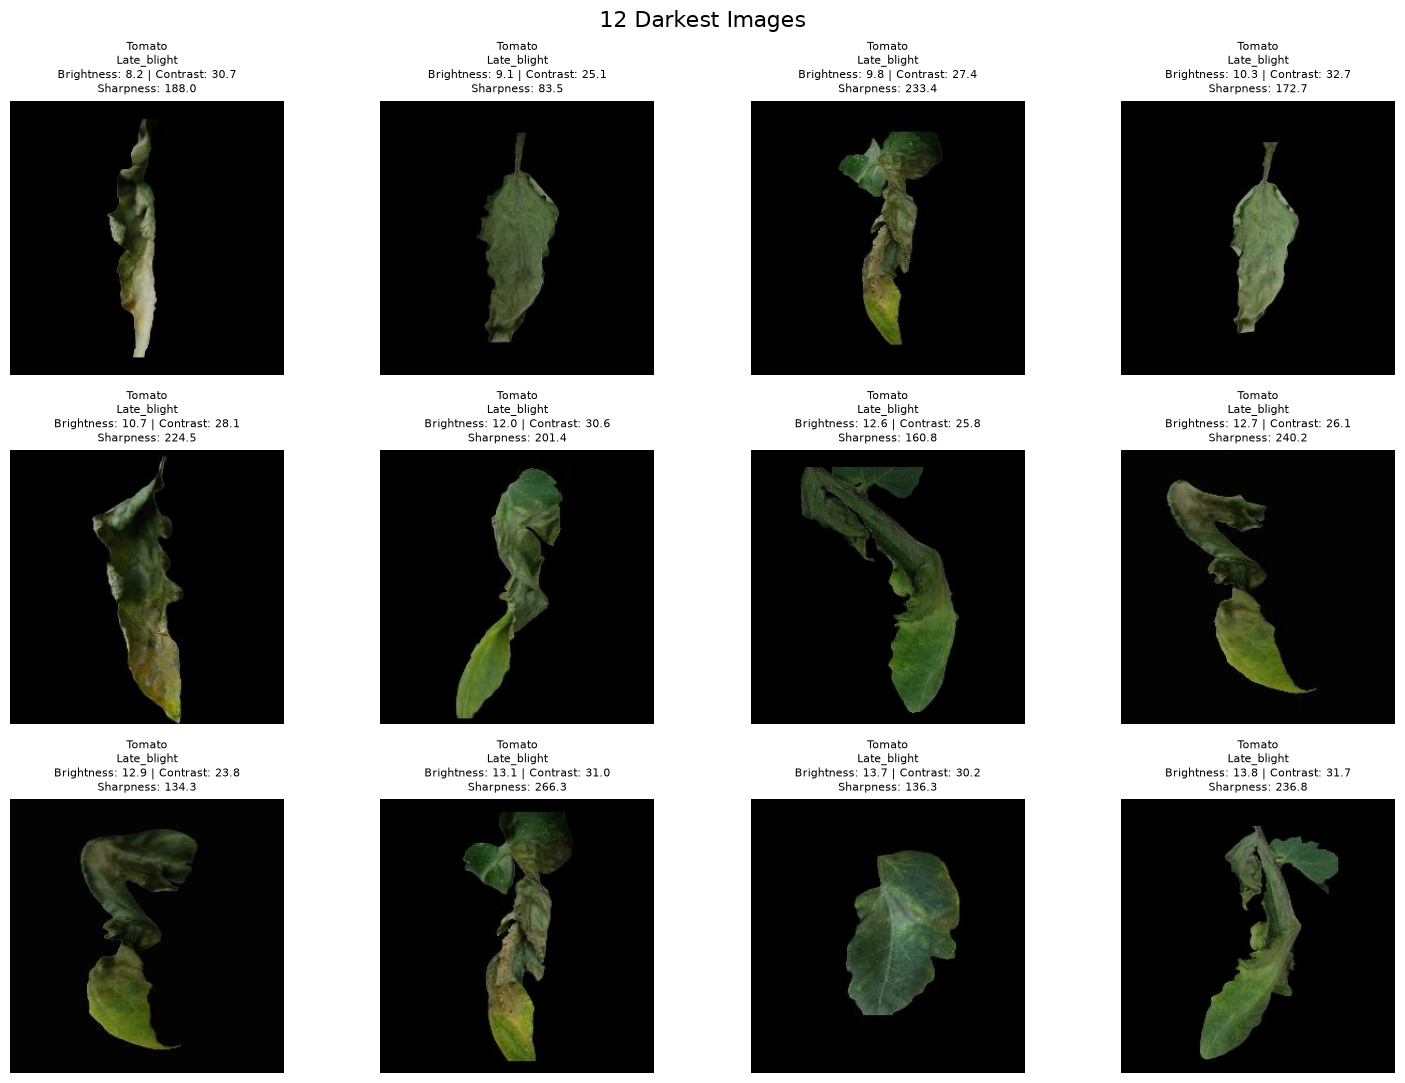

In [22]:
show_quality_samples(
    dark_images,
    "12 Darkest Images",
    metric="Brightness",
    n=12
)

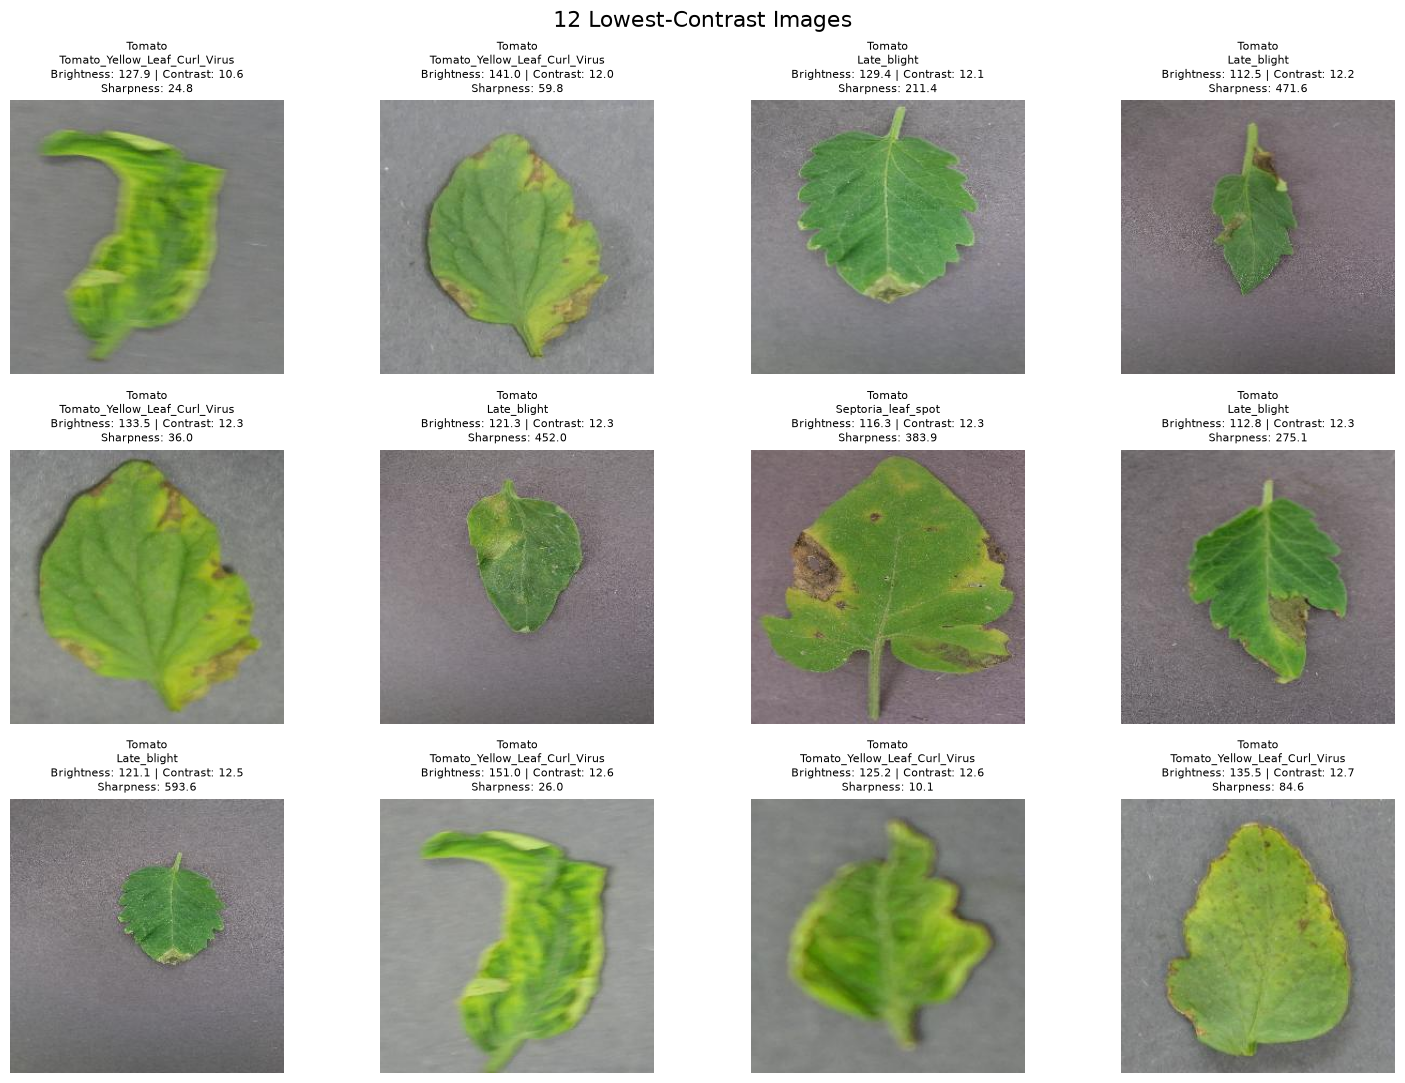

In [23]:
show_quality_samples(
    low_contrast_images,
    "12 Lowest-Contrast Images",
    metric="Contrast",
    n=12
)

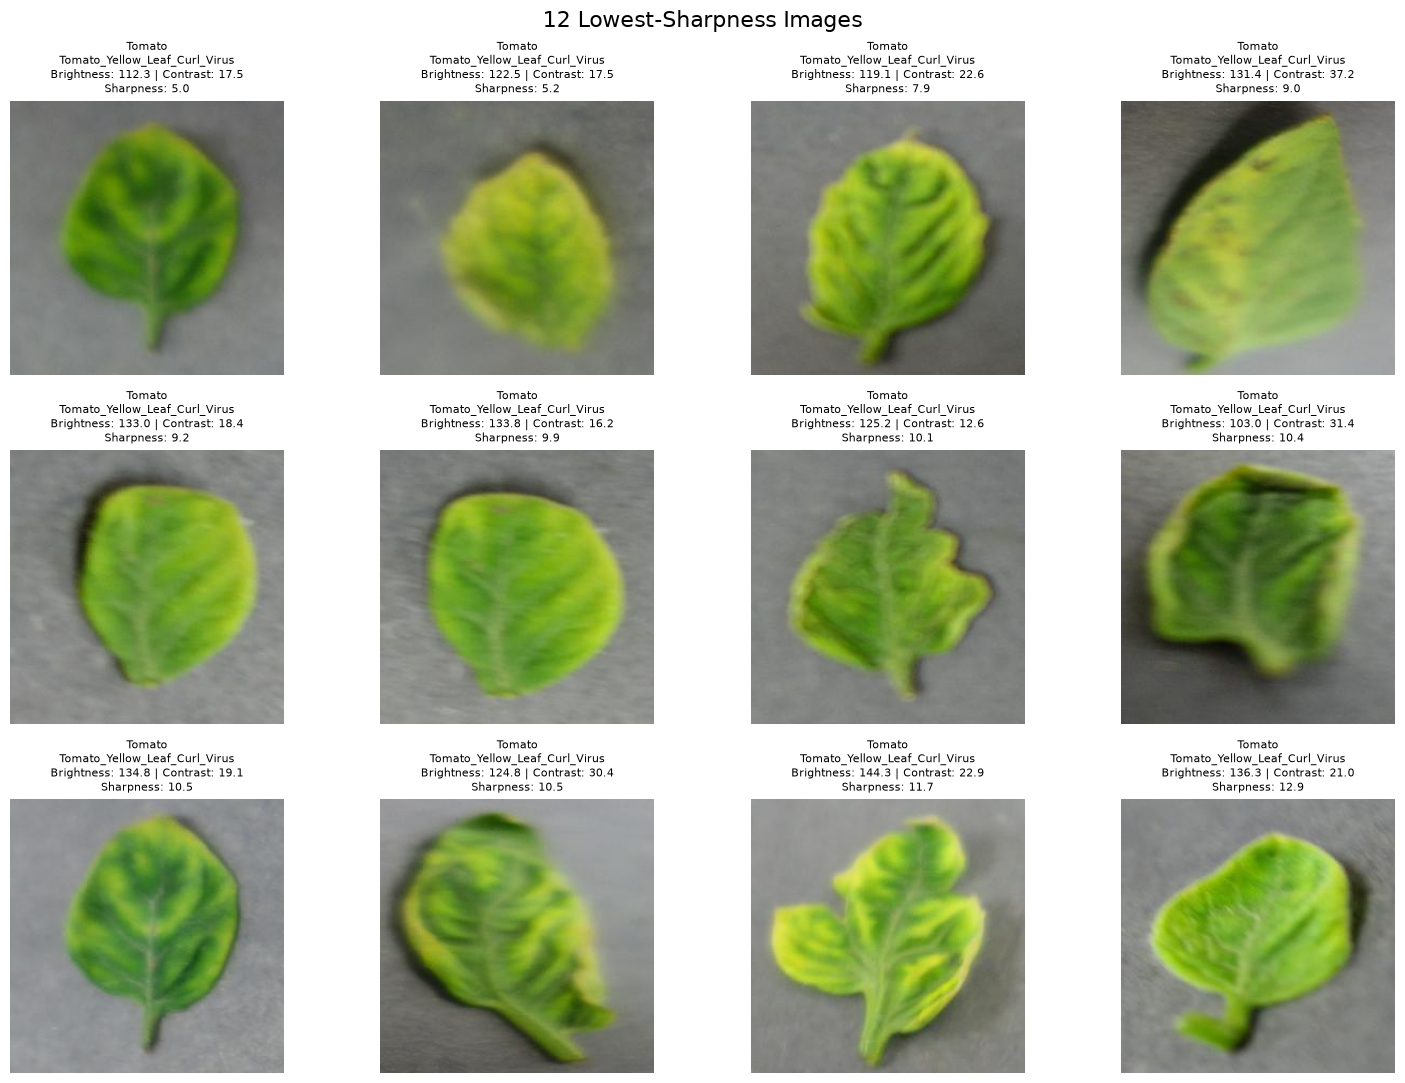

In [24]:
show_quality_samples(
    blurry_images,
    "12 Lowest-Sharpness Images",
    metric="Sharpness",
    n=12
)

In [25]:
flagged_paths = set(dark_images["Path"])
flagged_paths.update(low_contrast_images["Path"])
flagged_paths.update(blurry_images["Path"])

print("Dark:", len(dark_images))
print("Low contrast:", len(low_contrast_images))
print("Blurry:", len(blurry_images))

print("\nTotal unique flagged images:", len(flagged_paths))
print(
    "Percentage of dataset flagged:",
    round(len(flagged_paths) / len(quality_df) * 100, 2),
    "%"
)

Dark: 75
Low contrast: 626
Blurry: 414

Total unique flagged images: 1046
Percentage of dataset flagged: 5.15 %


In [26]:
from pathlib import Path
from PIL import Image
import hashlib

DATASET_DIR = Path("../data/processed/tomato_potato")

image_extensions = {".jpg", ".jpeg", ".png"}

expected_classes = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___healthy",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_mosaic_virus",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus"
]

print("=" * 60)
print("FINAL DATASET VALIDATION")
print("=" * 60)

# --------------------------------------------------
# 1. Check dataset path
# --------------------------------------------------

print("\n1. Dataset path")
print("Path:", DATASET_DIR.resolve())
print("Exists:", DATASET_DIR.exists())

# --------------------------------------------------
# 2. Check class folders
# --------------------------------------------------

actual_classes = sorted([
    folder.name
    for folder in DATASET_DIR.iterdir()
    if folder.is_dir()
])

print("\n2. Class validation")
print("Expected classes:", len(expected_classes))
print("Actual classes:", len(actual_classes))

missing_classes = sorted(set(expected_classes) - set(actual_classes))
unexpected_classes = sorted(set(actual_classes) - set(expected_classes))

print("Missing classes:", missing_classes)
print("Unexpected classes:", unexpected_classes)

# --------------------------------------------------
# 3. Count images per class
# --------------------------------------------------

print("\n3. Images per class")

class_counts = {}

for class_name in actual_classes:
    class_dir = DATASET_DIR / class_name

    count = sum(
        1 for file in class_dir.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    )

    class_counts[class_name] = count
    print(f"{class_name}: {count}")

total_images = sum(class_counts.values())

print("\nTotal images:", total_images)

# --------------------------------------------------
# 4. Check image readability and dimensions
# --------------------------------------------------

print("\n4. Image readability and dimensions")

unreadable_images = []
wrong_dimensions = []
image_count = 0

for class_name in actual_classes:

    class_dir = DATASET_DIR / class_name

    for image_path in class_dir.iterdir():

        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in image_extensions:
            continue

        image_count += 1

        try:
            with Image.open(image_path) as img:

                # Verify that image can actually be loaded
                img.verify()

            # Reopen after verify()
            with Image.open(image_path) as img:
                width, height = img.size

                if (width, height) != (256, 256):
                    wrong_dimensions.append(
                        (str(image_path), (width, height))
                    )

        except Exception:
            unreadable_images.append(str(image_path))

print("Images checked:", image_count)
print("Unreadable images:", len(unreadable_images))
print("Wrong dimensions:", len(wrong_dimensions))

# --------------------------------------------------
# 5. Check for exact duplicate images
# --------------------------------------------------

print("\n5. Exact duplicate validation")

hashes = {}
duplicate_groups = {}

for class_name in actual_classes:

    class_dir = DATASET_DIR / class_name

    for image_path in class_dir.iterdir():

        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in image_extensions:
            continue

        with open(image_path, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        if file_hash in hashes:
            duplicate_groups.setdefault(
                file_hash,
                [hashes[file_hash]]
            ).append(str(image_path))
        else:
            hashes[file_hash] = str(image_path)

print("Images hashed:", len(hashes))
print("Duplicate groups:", len(duplicate_groups))

# --------------------------------------------------
# 6. Final status
# --------------------------------------------------

print("\n" + "=" * 60)
print("FINAL VALIDATION SUMMARY")
print("=" * 60)

checks = {
    "Dataset exists": DATASET_DIR.exists(),
    "13 expected classes present":
        len(actual_classes) == 13 and
        len(missing_classes) == 0 and
        len(unexpected_classes) == 0,
    "Total images = 20,298": total_images == 20298,
    "All images readable": len(unreadable_images) == 0,
    "All images are 256x256": len(wrong_dimensions) == 0,
    "No exact duplicate groups": len(duplicate_groups) == 0
}

for check, result in checks.items():
    print(f"{'PASS' if result else 'FAIL'} — {check}")

all_passed = all(checks.values())

print("\nOverall validation:", "PASSED" if all_passed else "FAILED")

FINAL DATASET VALIDATION

1. Dataset path
Path: C:\Users\ATHARVA\Desktop\Mini project\ai-farmer-assistant\data\processed\tomato_potato
Exists: True

2. Class validation
Expected classes: 13
Actual classes: 13
Missing classes: []
Unexpected classes: []

3. Images per class
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152
Tomato___Bacterial_spot: 2127
Tomato___Early_blight: 1000
Tomato___Late_blight: 1901
Tomato___Leaf_Mold: 952
Tomato___Septoria_leaf_spot: 1771
Tomato___Spider_mites Two-spotted_spider_mite: 1676
Tomato___Target_Spot: 1404
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 5357
Tomato___Tomato_mosaic_virus: 373
Tomato___healthy: 1585

Total images: 20298

4. Image readability and dimensions
Images checked: 20298
Unreadable images: 0
Wrong dimensions: 0

5. Exact duplicate validation
Images hashed: 20298
Duplicate groups: 0

FINAL VALIDATION SUMMARY
PASS — Dataset exists
PASS — 13 expected classes present
PASS — Total images = 20,298
PASS — All images rea